# Setup

Throughout this project I tried to optimize the model's performances. I highly recommend using a GPU when running the project. Additionally i used the GPU cluster for some of the more intensive testing, dues some of the tests may be missing.

In [1]:
import torch
from torch import nn
from torch.utils.data import DataLoader
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.transforms import ToTensor
from torchvision.datasets import CIFAR10

import numpy as np
import matplotlib.pyplot as plt
import time

device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device")

torch.set_default_device(device)

Using cuda device


## Database

Download and load the *CIFAR10* data into DataLoader.


---


split the data into 3 types:

* Train: 40,000 images (~66.6%)
* Validation: 10,000 images (~16.6%)
* Test: 10,000 images (~16.6%)

In [2]:
classes = ('plane', 'car', 'bird', 'cat','deer',
           'dog', 'frog', 'horse', 'ship', 'truck')


def load_data(batch_size=128):
    transform = transforms.Compose(
        [ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
    )

    generator = torch.Generator(device=device)

    train_set = torchvision.datasets.CIFAR10(root='./data', train=True,
                                           download=True, transform=transform)

    train_size = int(0.8 * len(train_set))  # 80% for training
    val_size = len(train_set) - train_size  # 20% for validation
    train_set, val_set = torch.utils.data.random_split(train_set, [train_size, val_size],
                                                      generator=torch.Generator(device=device))

    train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size,
                                              shuffle=True, num_workers=0, pin_memory=False,
                                              generator=torch.Generator(device=device))

    val_loader = torch.utils.data.DataLoader(val_set, batch_size=batch_size,
                                              shuffle=True, num_workers=0, pin_memory=False,
                                              generator=torch.Generator(device=device))
    return train_loader, val_loader


def load_test(batch_size=128):
    transform = transforms.Compose(
        [ToTensor(),
         transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))]
    )

    test_set = torchvision.datasets.CIFAR10(root='./data', train=False,
                                           download=True, transform=transform)
    test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size,
                                             shuffle=False, num_workers=0,  pin_memory=True,
                                             generator=torch.Generator(device=device))
    return test_loader


## Utility funcations

In [3]:
def plot_loss(LOSS, Val_LOSS=None):
    plt.plot(LOSS, label='Training Loss')
    if Val_LOSS is not None:
        plt.plot(Val_LOSS, label='Validation Loss')
        plt.legend()
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.show()

def time_format(tm):
    houres = int(tm // 3600)
    tm = tm % 3600
    minutes = int(tm // 60)
    seconds = int(tm % 60)
    milliseconds = int((tm % 1) * 1000)
    return f"{houres:02}:{minutes:02}:{seconds:02}:{milliseconds:03}"

def accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data in loader:
            X, y = data
            X, y = X.to(device), y.to(device)
            outputs = model(X)
            _, predicted = torch.max(outputs.data, 1)
            total += y.size(0)
            correct += (predicted == y).sum().item()

    return 100 * correct / total

## Model Template

I created a flexible model template. The model requires an `nn.Sequential` containing the desired layers, activation functions and more... Additionally, the model contains a simple weights initialization function, mainly for CNN layers. And a train function with batch gradient descent

In [ ]:
class NeuralNetwork(nn.Module):
  def __init__(self, layers):

    super(NeuralNetwork, self).__init__()
    self.layers = layers

    # Set default optimizer and loss function
    self.optimizer = torch.optim.Adam(self.parameters())
    self.loss_fn = nn.MSELoss()

    self.initWeights()

  def forward(self, X):
    return self.layers(X)

  def fit(self, X, y):
    self.optimizer.zero_grad()
    y_pred = self.forward(X)
    loss = self.loss_fn(y_pred, y)
    loss.backward()
    self.optimizer.step()
    return loss.item()

  def initWeights(self):
    for m in self.modules():
        if isinstance(m, nn.Conv2d):
            nn.init.kaiming_normal_(m.weight, mode='fan_out',
                                    nonlinearity='relu')
            if m.bias is not None:
                nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.BatchNorm2d):
            nn.init.constant_(m.weight, 1)
            nn.init.constant_(m.bias, 0)
        elif isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, 0, 0.01)
            nn.init.constant_(m.bias, 0)

def train(model, train_loader, val_loader=None, epochs=20, enable_printing=True):
    model.train()
    LOSS = []
    Val_LOSS = []
    tm = time.time()
    if enable_printing:
        print('Starting Training')
    for epoch in range(epochs):  # loop over the dataset multiple times
        batch_loss = []
        for i, data in enumerate(train_loader, 0):
            X, y = data
            X, y = X.to(device), y.to(device)
            l = model.fit(X, y)
            batch_loss.append(l)

        LOSS.append(np.mean(batch_loss))
        if val_loader is not None:
            with torch.no_grad():
              val_batch_loss = []
              for i, data in enumerate(val_loader, 0):
                X_v, y_v = data
                X_v, y_v = X_v.to(device), y_v.to(device)
                y_pred = model.forward(X_v)
                loss = model.loss_fn(y_pred, y_v)
                val_batch_loss.append(loss.item())
              Val_LOSS.append(np.mean(val_batch_loss))
        if enable_printing:
            print(f'Epoch: {epoch+1:3} | {time_format(time.time() - tm)} | Loss: {LOSS[epoch]:.4f}')
    if enable_printing:
        print(f'Finished Training | {time_format(time.time() - tm)}')
    return LOSS if val_loader is None else (LOSS, Val_LOSS)

# Attempt 001

Starting with a model architecture inspired by lesson 9. My main goals where: getting a model up and running, estimate training time and needed model complexity.


> **Model** - A CNN Architecture as shown below, using 2 Convolution layers each followed by Relu and Max Pooling Layer. flatting to convert into a vector followed by a linear layer with 10 outputs for each class. finishing with Softmax for a probability vector.

> **Loss Function** - Log Loss, due to classification problem

> **Optimizer** - Adam optimizer

> **Learning Rate** - arbitrary set to `0.001`

In [ ]:
# By default batch_size=128
train_loader, val_loader = load_data()

Files already downloaded and verified


Starting Training


site-packages/torch/nn/functional.py:1854: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return handle_torch_function(softmax, (input,), input, dim=dim, _stacklevel=_stacklevel, dtype=dtype)


Epoch:   1 | 00:00:11:243 | Loss: 2.0674
Epoch:   2 | 00:00:20:405 | Loss: 1.9683
Epoch:   3 | 00:00:29:467 | Loss: 1.9271
Epoch:   4 | 00:00:38:487 | Loss: 1.8900
Epoch:   5 | 00:00:47:503 | Loss: 1.8623
Epoch:   6 | 00:00:56:546 | Loss: 1.8408
Epoch:   7 | 00:01:06:169 | Loss: 1.8197
Epoch:   8 | 00:01:16:426 | Loss: 1.8044
Epoch:   9 | 00:01:27:007 | Loss: 1.7935
Epoch:  10 | 00:01:36:119 | Loss: 1.7799
Epoch:  11 | 00:01:45:182 | Loss: 1.7706
Epoch:  12 | 00:01:54:293 | Loss: 1.7605
Epoch:  13 | 00:02:03:447 | Loss: 1.7509
Epoch:  14 | 00:02:12:671 | Loss: 1.7449
Epoch:  15 | 00:02:21:823 | Loss: 1.7354
Finished Training | 00:02:21:823
train accuracy:  74.1875
validation accuracy:  65.09


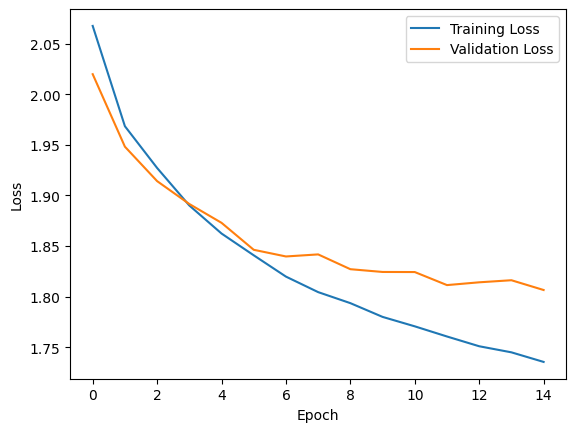

In [ ]:
layers = nn.Sequential(
        nn.Conv2d(3, 16, 5, 1, 2),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 5, 1, 2),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(2048, 10),
        nn.Softmax()
    )

model = NeuralNetwork(layers)
model.optimizer = optim.Adam(model.parameters(), lr=0.001)
model.loss_fn = nn.CrossEntropyLoss()

LOSS, val_LOSS= train(model, train_loader, val_loader, 15)
print("train accuracy: ", accuracy(model, train_loader))
print("validation accuracy: ", accuracy(model, val_loader))
plot_loss(LOSS, val_LOSS)

 **Conclusion:**
 - Both training and validation loss decreased over the epochs, indicating that the model was learning the patterns in the training data.
 - As can be expected form the first attempt, the model suffers from high bias
 - Variance seems to be in a acceptable range
 - Overall for a first attempt with next to none optimization, the model looks promising

 > ***Next objective: Lower bias***

# Attempt 002

In this attemp ill try to find a model architecture with faster converagnce. dues achiving lower bias.  i'll keep the learning parametes(learning rate, ephocs) for better comperstion.

In [ ]:
# By default batch_size=128
train_loader, val_loader = load_data()

100%|██████████| 170M/170M [00:02<00:00, 71.9MB/s]


Extracting ./data/cifar-10-python.tar.gz to ./data


### Model 001:
- Adding complexity to the network
- Bigger kernel in first convolutional layer
- Added another convolutional layer

Starting Training


site-packages/torch/nn/functional.py:1854: UserWarning: Implicit dimension choice for softmax has been deprecated. Change the call to include dim=X as an argument.
  return handle_torch_function(softmax, (input,), input, dim=dim, _stacklevel=_stacklevel, dtype=dtype)


Epoch:   1 | 00:00:11:649 | Loss: 2.1066
Epoch:   2 | 00:00:21:472 | Loss: 2.0187
Epoch:   3 | 00:00:31:336 | Loss: 1.9739
Epoch:   4 | 00:00:41:059 | Loss: 1.9376
Epoch:   5 | 00:00:53:041 | Loss: 1.9089
Epoch:   6 | 00:01:02:864 | Loss: 1.8872
Epoch:   7 | 00:01:15:562 | Loss: 1.8662
Epoch:   8 | 00:01:28:342 | Loss: 1.8445
Epoch:   9 | 00:01:41:369 | Loss: 1.8324
Epoch:  10 | 00:01:54:189 | Loss: 1.8179
Epoch:  11 | 00:02:07:171 | Loss: 1.8027
Epoch:  12 | 00:02:19:432 | Loss: 1.7894
Epoch:  13 | 00:02:32:611 | Loss: 1.7763
Epoch:  14 | 00:02:45:681 | Loss: 1.7633
Epoch:  15 | 00:02:58:750 | Loss: 1.7538
Finished Training | 00:02:58:750
train accuracy:  70.8625
validation accuracy:  60.3


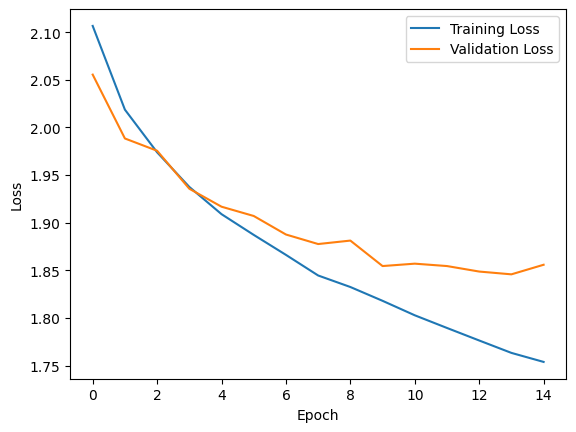

In [ ]:
layers = nn.Sequential(
        nn.Conv2d(3, 16, 10, 1, 2),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 5, 1, 2),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 64, 5, 1, 2),
        nn.ReLU(),
        nn.Flatten(),
        nn.Linear(2304, 10),
        nn.Softmax()
    )

model = NeuralNetwork(layers)
model.optimizer = optim.Adam(model.parameters(), lr=0.001)
model.loss_fn = nn.CrossEntropyLoss()

LOSS, val_LOSS= train(model, train_loader, val_loader, 15)
print("train accuracy: ", accuracy(model, train_loader))
print("validation accuracy: ", accuracy(model, val_loader))
plot_loss(LOSS, val_LOSS)

 **Conclution:**
 - No significant change from the base model

### Model 002:
- Added batch norm after every convolutional layer for accelerated converangce

Starting Training
Epoch:   1 | 00:00:12:667 | Loss: 2.0884
Epoch:   2 | 00:00:24:645 | Loss: 1.9434
Epoch:   3 | 00:00:35:579 | Loss: 1.8900
Epoch:   4 | 00:00:47:063 | Loss: 1.8417
Epoch:   5 | 00:00:59:266 | Loss: 1.8164
Epoch:   6 | 00:01:11:439 | Loss: 1.7951
Epoch:   7 | 00:01:21:182 | Loss: 1.7789
Epoch:   8 | 00:01:30:498 | Loss: 1.7658
Epoch:   9 | 00:01:41:068 | Loss: 1.7548
Epoch:  10 | 00:01:52:712 | Loss: 1.7462
Epoch:  11 | 00:02:05:305 | Loss: 1.7389
Epoch:  12 | 00:02:17:053 | Loss: 1.7319
Epoch:  13 | 00:02:29:324 | Loss: 1.7223
Epoch:  14 | 00:02:41:636 | Loss: 1.7155
Epoch:  15 | 00:02:53:898 | Loss: 1.7113
Finished Training | 00:02:53:898
train accuracy:  77.615
validation accuracy:  69.32


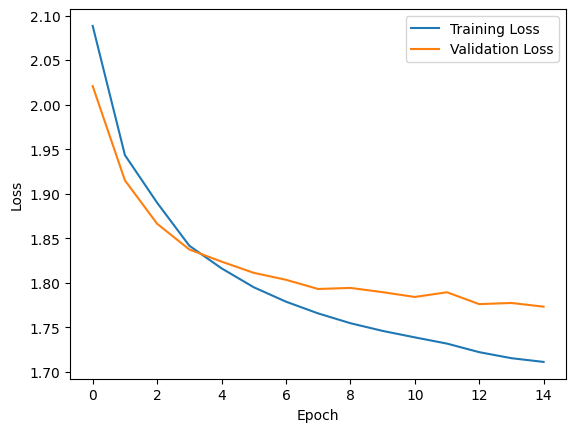

In [ ]:
layers = nn.Sequential(
        nn.Conv2d(3, 16, 5, 1, 2),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(16, 32, 5, 1, 2),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Flatten(),
        nn.Linear(2048, 10),
        nn.Softmax()
    )

model = NeuralNetwork(layers)
model.optimizer = optim.Adam(model.parameters(), lr=0.001)
model.loss_fn = nn.CrossEntropyLoss()

LOSS, val_LOSS= train(model, train_loader, val_loader, 15)
print("train accuracy: ", accuracy(model, train_loader))
print("validation accuracy: ", accuracy(model, val_loader))
plot_loss(LOSS, val_LOSS)

 **Conclusion:**
- As anticipated batch norm accelerated convergence

### Model 003:
- Replace pooling layers with conventional layers
- hoping to increase complexity

Starting Training
Epoch:   1 | 00:00:09:529 | Loss: 2.0435
Epoch:   2 | 00:00:19:040 | Loss: 1.9376
Epoch:   3 | 00:00:30:383 | Loss: 1.8910
Epoch:   4 | 00:00:42:107 | Loss: 1.8630
Epoch:   5 | 00:00:54:063 | Loss: 1.8384
Epoch:   6 | 00:01:06:200 | Loss: 1.8170
Epoch:   7 | 00:01:18:555 | Loss: 1.7966
Epoch:   8 | 00:01:29:374 | Loss: 1.7801
Epoch:   9 | 00:01:41:443 | Loss: 1.7651
Epoch:  10 | 00:01:52:396 | Loss: 1.7542
Epoch:  11 | 00:02:04:718 | Loss: 1.7468
Epoch:  12 | 00:02:17:360 | Loss: 1.7349
Epoch:  13 | 00:02:29:815 | Loss: 1.7235
Epoch:  14 | 00:02:42:302 | Loss: 1.7150
Epoch:  15 | 00:02:54:556 | Loss: 1.7069
Finished Training | 00:02:54:557
train accuracy:  76.85
validation accuracy:  65.94


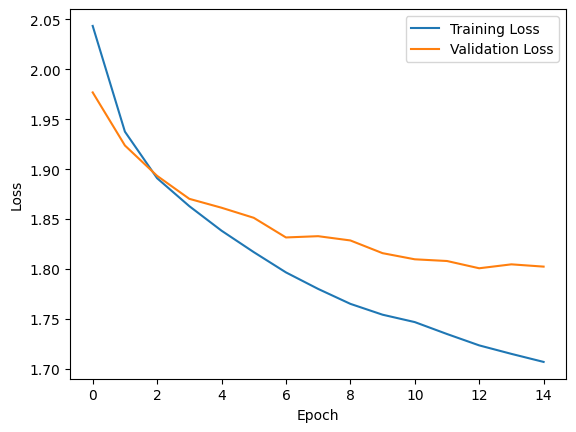

In [ ]:
layers = nn.Sequential(
        nn.Conv2d(3, 16, 5, 1, 2),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.Conv2d(16, 16, 2, 2),
        nn.ReLU(),
        nn.Conv2d(16, 32, 5, 1, 2),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.Conv2d(32, 32, 2, 2),
        nn.ReLU(),
        nn.Flatten(),
        nn.Linear(2048, 10),
        nn.Softmax()
    )

model = NeuralNetwork(layers)
model.optimizer = optim.Adam(model.parameters(), lr=0.001)
model.loss_fn = nn.CrossEntropyLoss()

LOSS, val_LOSS= train(model, train_loader, val_loader, 15)
print("train accuracy: ", accuracy(model, train_loader))
print("validation accuracy: ", accuracy(model, val_loader))
plot_loss(LOSS, val_LOSS)

 **Conclusion:**
- seems to increase variance but not lower bias

### Model 004:
- Again, Trying to add complexity by adding more layers to the network.
- This time I'll add linear layers in the end of the model followed by ReLU
- Additionally I'll add more convolution layers

Starting Training
Epoch:   1 | 00:00:10:840 | Loss: 2.1854
Epoch:   2 | 00:00:21:593 | Loss: 2.1181
Epoch:   3 | 00:00:33:335 | Loss: 2.1010
Epoch:   4 | 00:00:46:372 | Loss: 2.0984
Epoch:   5 | 00:00:58:750 | Loss: 2.0780
Epoch:   6 | 00:01:10:716 | Loss: 2.0994
Epoch:   7 | 00:01:22:761 | Loss: 2.0882
Epoch:   8 | 00:01:36:022 | Loss: 2.0954
Epoch:   9 | 00:01:49:170 | Loss: 2.1134
Epoch:  10 | 00:02:02:710 | Loss: 2.1204
Epoch:  11 | 00:02:16:282 | Loss: 2.0893
Epoch:  12 | 00:02:30:036 | Loss: 2.0570
Epoch:  13 | 00:02:43:719 | Loss: 2.0857
Epoch:  14 | 00:02:57:492 | Loss: 2.0916
Epoch:  15 | 00:03:11:104 | Loss: 2.0852
Finished Training | 00:03:11:105
train accuracy:  39.9125
validation accuracy:  39.8


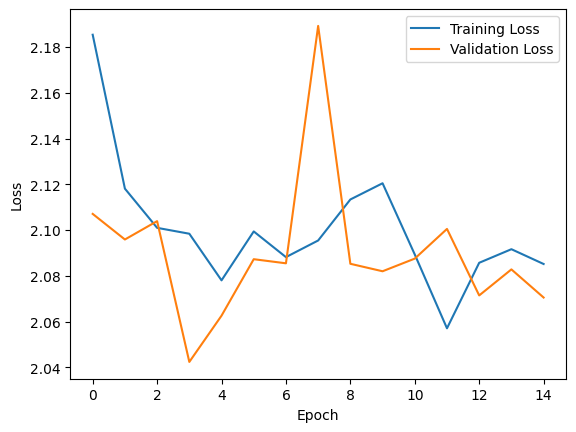

In [ ]:
layers = nn.Sequential(
        nn.Conv2d(3, 16, 5, 1, 2),
        nn.BatchNorm2d(16),
        nn.ReLU(),
        nn.Conv2d(16, 32, 5, 1, 2),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(32, 48, 5, 1, 2),
        nn.BatchNorm2d(48),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(48, 64, 5, 1, 2),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.Flatten(),
        nn.Linear(4096, 2048),
        nn.ReLU(),
        nn.Linear(2048, 1024),
        nn.ReLU(),
        nn.Linear(1024, 10),
        nn.Softmax()
    )

model = NeuralNetwork(layers)
model.optimizer = optim.Adam(model.parameters(), lr=0.001)
model.loss_fn = nn.CrossEntropyLoss()

LOSS, val_LOSS= train(model, train_loader, val_loader, 15)
print("train accuracy: ", accuracy(model, train_loader))
print("validation accuracy: ", accuracy(model, val_loader))
plot_loss(LOSS, val_LOSS)

**Conclusions:**
- Model is overloaded, not performing too good

**Attempt Conclusions:**
- Best model so far is the first model with batch norm (model 002)

# Attempt 003

In this attempt I'll try to lower bias by optimizing learning rate.
I'll start by searching learning rate in log space in the range of [0.1, 0.0001]

In [ ]:
# By default batch_size=128
train_loader, val_loader = load_data()

Files already downloaded and verified


In [ ]:
def run_model(lr):
    layers = nn.Sequential(
            nn.Conv2d(3, 16, 5, 1, 2),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 5, 1, 2),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(2048, 10),
            nn.Softmax(dim=1)
        )

    model = NeuralNetwork(layers)
    model.optimizer = optim.Adam(model.parameters(), lr=lr)
    model.loss_fn = nn.CrossEntropyLoss()

    train(model, train_loader, val_loader, 15, enable_printing=True)
    acc_train = accuracy(model, train_loader)
    acc_val = accuracy(model, val_loader)
    return acc_train, acc_val

In [ ]:
searchable_learning_rates = [10**(-5 * np.random.uniform(0.5, 1)) for _ in range(100)]
train_accuracies = []
val_accuracies = []

for lr in searchable_learning_rates:
    acc_train, acc_val = run_model(lr)
    train_accuracies.append(acc_train)
    val_accuracies.append(acc_val)

The search is computationally expensive (run time of 5 hours), I ran the algorithm in the GPU cluster and outputted into a file

In [ ]:
searchable_learning_rates = np.loadtxt("results/lr_output.txt", usecols=0)
train_accuracies = np.loadtxt("results/lr_output.txt", usecols=1)
val_accuracies = np.loadtxt("results/lr_output.txt", usecols=2)

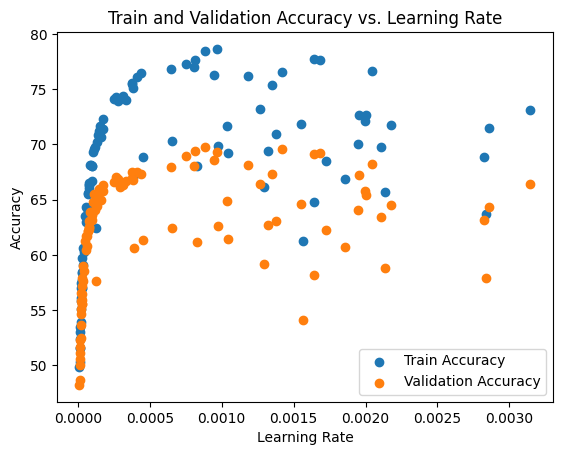

In [ ]:
plt.scatter(searchable_learning_rates, train_accuracies, label='Train Accuracy')
plt.scatter(searchable_learning_rates, val_accuracies, label='Validation Accuracy')
plt.xlabel('Learning Rate')
plt.ylabel('Accuracy')
plt.title('Train and Validation Accuracy vs. Learning Rate')
plt.legend()
plt.show()

In [ ]:
best_train = max(train_accuracies)
x = np.where(train_accuracies==best_train)

best_val = max(val_accuracies)
y = np.where(val_accuracies==best_val)

(array([2]),) (array([95]),)


In [ ]:
print(searchable_learning_rates[x[0]],train_accuracies[x[0]], val_accuracies[x[0]])

[0.00096641] [78.645] [69.27]


In [ ]:
print(searchable_learning_rates[y[0]], train_accuracies[y[0]], val_accuracies[y[0]])

[0.00088289] [78.4725] [69.79]


**Conclusions:**
- Found an effective learning rate for the model

# Attempt 004

Increase epochs, in order to lower bias

In this attempt i used a learning rate of `0.00096641` with the previously used model

I set `epochs = 150`

Finished Training | 00:23:43:933
train accuracy 90.9025
validation accuracy 69.85


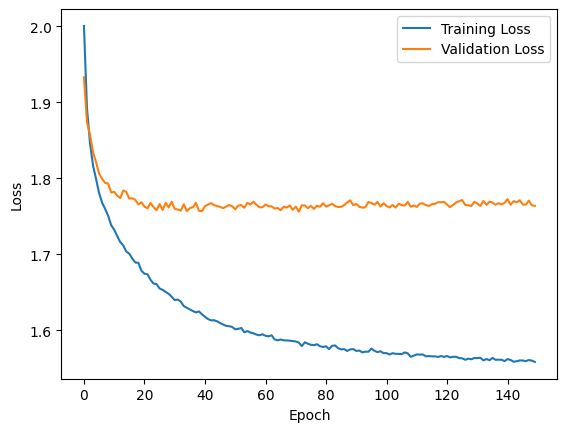

In [ ]:
with open("results/attempt_004.txt", "r") as f:
    print(f.read())
LOSS = np.loadtxt("results/attempt_004_loss.txt", usecols=0)
val_LOSS = np.loadtxt("results/attempt_004_loss.txt", usecols=1)
plot_loss(LOSS, val_LOSS)

**Conclusions:**
- Bias went down (Although not enough)
- Variance went down

 > ***Next objective: Lower Variance***

# Attempt 005

Implement regulation in order to lower variance.

I'll add to the model:
- weight decay
- early stopping
- dropout

I'll redefine train function to include an early stopping option with default patience of 5

In [ ]:
def train(model, train_loader, val_loader=None, epochs=20, patience=5, early_stopping=False, enable_printing=True):
    model.train()
    LOSS = []
    Val_LOSS = []
    tm = time.time()
    best_val_loss = float('inf')
    epochs_no_improve = 0
    early_stop = False

    if enable_printing:
        print('Starting Training')

    for epoch in range(epochs):  # loop over the dataset multiple times
        if early_stop and early_stopping:
            break

        # Training phase
        batch_loss = []
        for i, data in enumerate(train_loader, 0):
            X, y = data
            X, y = X.to(device), y.to(device)
            l = model.fit(X, y)
            batch_loss.append(l)
        LOSS.append(np.mean(batch_loss))

        # Validation phase
        if val_loader is not None:
            with torch.no_grad():
                val_batch_loss = []
                for i, data in enumerate(val_loader, 0):
                    X_v, y_v = data
                    X_v, y_v = X_v.to(device), y_v.to(device)
                    y_pred = model.forward(X_v)
                    loss = model.loss_fn(y_pred, y_v)
                    val_batch_loss.append(loss.item())
                val_loss = np.mean(val_batch_loss)
                Val_LOSS.append(val_loss)

                # Early stopping logic
                if early_stopping:
                    if val_loss < best_val_loss:
                        best_val_loss = val_loss
                        epochs_no_improve = 0
                    else:
                        epochs_no_improve += 1

                    if epochs_no_improve >= patience:
                        if enable_printing:
                            print(f"Early stopping triggered after {epoch + 1} epochs")
                        early_stop = True
                        break

        if enable_printing:
            print(f"Epoch: {epoch + 1:3} | {time_format(time.time() - tm)} | Loss: {LOSS[epoch]:.4f}", end="")
            if val_loader is not None:
                print(f" | Val Loss: {Val_LOSS[-1]:.4f}")
            else:
                print()

    if enable_printing and not early_stop:
        print(f"Finished Training | {time_format(time.time() - tm)}")
    return LOSS if val_loader is None else (LOSS, Val_LOSS)


Additionally i added run/train function similar to before, with added dropout and weight_decay

In [ ]:
# By default batch_size=128
train_loader, val_loader = load_data()

Files already downloaded and verified


In [ ]:
def run_model(lr=0.00096641, dropout_rate=0.3, weight_decay=1e-4, enable_printing=False):
    layers = nn.Sequential(
            nn.Dropout(dropout_rate),
            nn.Conv2d(3, 16, 5, 1, 2),
            nn.BatchNorm2d(16),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(16, 32, 5, 1, 2),
            nn.BatchNorm2d(32),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(2048, 10),
            nn.Softmax(dim=1)
        )

    model = NeuralNetwork(layers)
    model.optimizer = optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)
    model.loss_fn = nn.CrossEntropyLoss()


    train(model, train_loader, val_loader, 15, enable_printing=enable_printing)
    acc_train = accuracy(model, train_loader)
    acc_val = accuracy(model, val_loader)
    return acc_train, acc_val

In [ ]:
run_model(enable_printing=True)

Starting Training
Epoch:   1 | 00:00:11:980 | Loss: 2.0726 | Val Loss: 1.9973
Epoch:   2 | 00:00:21:574 | Loss: 1.9534 | Val Loss: 1.9328
Epoch:   3 | 00:00:30:926 | Loss: 1.9129 | Val Loss: 1.9098
Epoch:   4 | 00:00:40:807 | Loss: 1.8885 | Val Loss: 1.9015
Epoch:   5 | 00:00:51:580 | Loss: 1.8687 | Val Loss: 1.8708
Epoch:   6 | 00:01:02:872 | Loss: 1.8552 | Val Loss: 1.8641
Epoch:   7 | 00:01:13:432 | Loss: 1.8423 | Val Loss: 1.8556
Epoch:   8 | 00:01:24:228 | Loss: 1.8325 | Val Loss: 1.8486
Epoch:   9 | 00:01:34:526 | Loss: 1.8266 | Val Loss: 1.8551
Epoch:  10 | 00:01:45:239 | Loss: 1.8180 | Val Loss: 1.8409
Epoch:  11 | 00:01:55:839 | Loss: 1.8151 | Val Loss: 1.8421
Epoch:  12 | 00:02:05:584 | Loss: 1.8092 | Val Loss: 1.8365
Epoch:  13 | 00:02:16:417 | Loss: 1.8047 | Val Loss: 1.8380
Epoch:  14 | 00:02:26:250 | Loss: 1.7995 | Val Loss: 1.8360
Epoch:  15 | 00:02:36:721 | Loss: 1.7960 | Val Loss: 1.8405
Finished Training | 00:02:36:721


(63.93, 60.06)

Finished Training | 00:02:36:721
train accuracy 63.93
validation accuracy 60.06


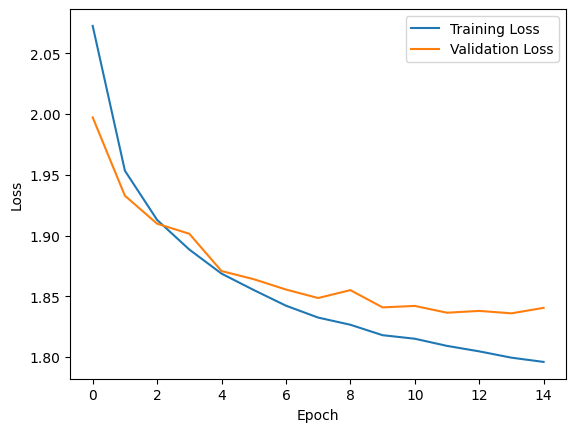

In [ ]:
with open("results/attempt_005.txt", "r") as f:
    print(f.read())
LOSS = np.loadtxt("results/attempt_005_loss.txt", usecols=0)
val_LOSS = np.loadtxt("results/attempt_005_loss.txt", usecols=1)
plot_loss(LOSS, val_LOSS)

**Conclusions:**
- Variance decreased drastically
- But bias as well

 > ***Next objective: Try training with more epochs***

# Attempt 006

I calculated the same model from last attempt with `epochs = 1000`

Early stopping triggered after 214 epochs
train accuracy: 70.355
validation accuracy: 60.8



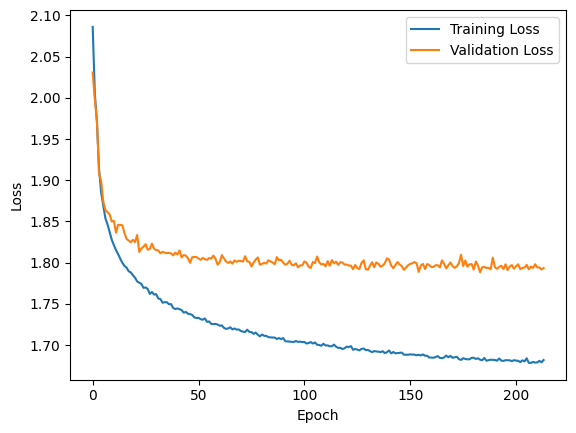

In [ ]:
with open("results/attempt_006.txt", "r") as f:
    print(f.read())
LOSS = np.loadtxt("results/attempt_006_loss.txt", usecols=0)
val_LOSS = np.loadtxt("results/attempt_006_loss.txt", usecols=1)
plot_loss(LOSS, val_LOSS)

**Conclusions:**

- I've tried various combinations of the 3 regulation mechanics i implemented but as shown in above cell they all capped at around 75% for train accuracy.
- Additionally, the results seems to suffer from a high bias or high variance.

# Attempt 007

In all of my last attempts the validation accuracy did not exceed 70%, thus I'll try using a different architecture.

I'll be using ResNet50 with pre-trained parameters.

TO do that I'll need to make some adjustments:
- resize input to 224X224.
- resize model output to match CIFAR10

#### Resize Input

In [ ]:
classes = ('plane', 'car', 'bird', 'cat','deer',
           'dog', 'frog', 'horse', 'ship', 'truck')


def load_data(batch_size=128):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),  # Resize to match ResNet50 input size
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  # Normalize values to [-1, 1]
    ])
    generator = torch.Generator(device=device)

    train_set = torchvision.datasets.CIFAR10(root='./data', train=True,
                                           download=True, transform=transform)

    train_size = int(0.8 * len(train_set))  # 80% for training
    val_size = len(train_set) - train_size  # 20% for validation
    train_set, val_set = torch.utils.data.random_split(train_set, [train_size, val_size],
                                                      generator=torch.Generator(device=device))

    train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size,
                                              shuffle=True, num_workers=0, pin_memory=False,
                                              generator=torch.Generator(device=device))

    val_loader = torch.utils.data.DataLoader(val_set, batch_size=batch_size,
                                              shuffle=True, num_workers=0, pin_memory=False,
                                              generator=torch.Generator(device=device))
    return train_loader, val_loader


def load_test(batch_size=128):
    transform = transforms.Compose([
        transforms.Resize((224, 224)),  # Resize to match ResNet50 input size
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])  # Normalize values to [-1, 1]
    ])

    test_set = torchvision.datasets.CIFAR10(root='./data', train=False,
                                           download=True, transform=transform)
    test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size,
                                             shuffle=False, num_workers=0,  pin_memory=True,
                                             generator=torch.Generator(device=device))
    return test_loader


#### Load ResNet50 and resize output

In [ ]:
from torchvision.models import resnet50

resnet50 = resnet50(weights=True)
in_features = resnet50.fc.in_features
resnet50.fc = nn.Sequential(
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )


In [ ]:
from types import MethodType

def fit(self, X, y):
    self.optimizer.zero_grad()
    y_pred = self.forward(X)
    loss = self.loss_fn(y_pred, y)
    loss.backward()
    self.optimizer.step()
    return loss.item()

resnet50.fit = MethodType(fit, resnet50)

In [ ]:
# By default batch_size=128
train_loader, val_loader = load_data()

In [ ]:
resnet50.optimizer = optim.Adam(resnet50.parameters(), lr=0.001)
resnet50.loss_fn = nn.CrossEntropyLoss()
LOSS, val_LOSS= train(resnet50, train_loader, val_loader, 10)
print("train accuracy: ", accuracy(resnet50, train_loader))
print("validation accuracy: ", accuracy(resnet50, val_loader))
plot_loss(LOSS, val_LOSS)

#### Results:

training parameters:
- Epochs: `10`
- Learning rate: `0.001`

Finished Training | 00:25:51:028
train accuracy:  98.735
validation accuracy:  90.66


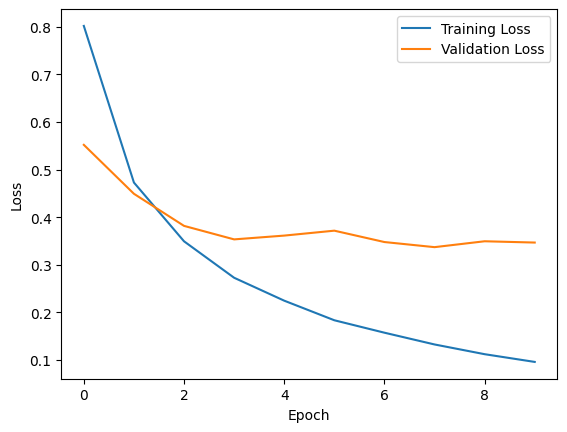

In [ ]:
with open("results/attempt_007.txt", "r") as f:
    print(f.read())
LOSS = np.loadtxt("results/attempt_007_loss.txt", usecols=0)
val_LOSS = np.loadtxt("results/attempt_007_loss.txt", usecols=1)
plot_loss(LOSS, val_LOSS)

**Conclusions:**

- Not surprisingly ResNet50 preformed exceptionally well
- The lowest bias and variance I've achieved
- Variance can be lower...
> ***Next objective: Lower Variance***

# Attempt 008

Adjusted the transformation in the input functions, for values specific to CIFAR-10, meaning they are computed as the mean and standard deviation of the training set.

Additionally, I've added Random Horizontal Flip to the train's data transform to add variance.

In [ ]:
def load_data(batch_size=128):

    # values specific to CIFAR-10, meaning they are computed as the mean and standard deviation of the training set.


    # Train and Validation sets transformtions
    normalize = transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2023, 0.1994, 0.2010],
    )
    transform_train = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.RandomHorizontalFlip(0.5),
        transforms.ToTensor(),
        normalize,
    ])
    transform_val = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        normalize,
    ])
    generator = torch.Generator(device=device)

    train_set = torchvision.datasets.CIFAR10(root='./data', train=True,
                                           download=True, transform=transform_train)


    train_size = int(0.8 * len(train_set))  # 80% for training
    val_size = len(train_set) - train_size  # 20% for validation
    train_set, val_set = torch.utils.data.random_split(train_set, [train_size, val_size],
                                                      generator=torch.Generator(device=device))

    val_set.dataset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                           download=True, transform=transform_val)

    train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size,
                                              shuffle=True, num_workers=0, pin_memory=False,
                                              generator=torch.Generator(device=device))

    val_loader = torch.utils.data.DataLoader(val_set, batch_size=batch_size,
                                              shuffle=True, num_workers=0, pin_memory=False,
                                              generator=torch.Generator(device=device))
    return train_loader, val_loader


def load_test(batch_size=128):

    # Test set transformtion
    normalize = transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    )
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        normalize,
    ])

    test_set = torchvision.datasets.CIFAR10(root='./data', train=False,
                                           download=True, transform=transform)
    test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size,
                                             shuffle=False, num_workers=0,  pin_memory=True,
                                             generator=torch.Generator(device=device))
    return test_loader


For the next attempts I'll be using the previous model (attempt 007), and I'll be changing various hyper-parameters.

## attempt 8.1

hyper-parameters are the same for attempt 007

In [ ]:
from torchvision.models import resnet50

# Load ResNet50 with pretrained weights
resnet50 = resnet50(weights=True)
# Replace ResNet50 last fully connected layers to output 10 features
in_features = resnet50.fc.in_features

resnet50.fc = nn.Sequential(
            nn.Dropout(0),
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

from types import MethodType

def fit(self, X, y):
    self.optimizer.zero_grad()
    y_pred = self.forward(X)
    loss = self.loss_fn(y_pred, y)
    loss.backward()
    self.optimizer.step()
    return loss.item()

resnet50.fit = MethodType(fit, resnet50)

# By default batch_size=128
train_loader, val_loader = load_data(128)

resnet50.optimizer = optim.Adam(resnet50.parameters(), lr=0.001, weight_decay=0)
resnet50.loss_fn = nn.CrossEntropyLoss(label_smoothing=0.0)
LOSS, val_LOSS= train(resnet50, train_loader, val_loader, 10)

train accuracy: 97.16
validation accuracy: 91.09


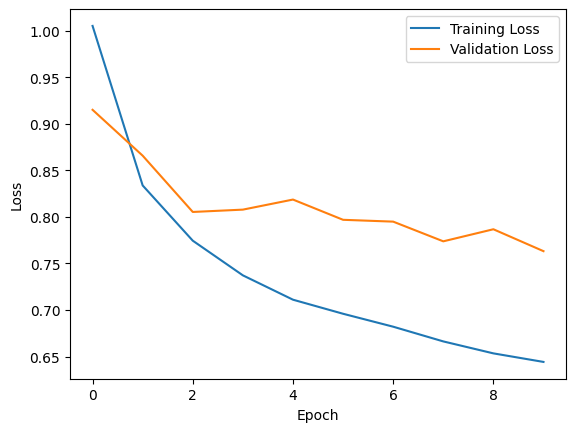

In [74]:
with open("results/attempt8_1.txt", "r") as f:
    print(f.read())
LOSS = np.loadtxt("results/attempt8_1_loss.txt", usecols=0)
val_LOSS = np.loadtxt("results/attempt8_1_loss.txt", usecols=1)
plot_loss(LOSS, val_LOSS)

**Conclusions:**
- The augmentation of the transformation lowered variance by a bit

## attempt 8.2

Added dropout rate of `0.2`

In [ ]:

from torchvision.models import resnet50

# Load ResNet50 with pretrained weights
resnet50 = resnet50(weights=True)
# Replace ResNet50 last fully connected layers to output 10 features
in_features = resnet50.fc.in_features

resnet50.fc = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

from types import MethodType

def fit(self, X, y):
    self.optimizer.zero_grad()
    y_pred = self.forward(X)
    loss = self.loss_fn(y_pred, y)
    loss.backward()
    self.optimizer.step()
    return loss.item()

resnet50.fit = MethodType(fit, resnet50)

# By default batch_size=128
train_loader, val_loader = load_data(128)

resnet50.optimizer = optim.Adam(resnet50.parameters(), lr=0.001, weight_decay=0)
resnet50.loss_fn = nn.CrossEntropyLoss(label_smoothing=0.0)
LOSS, val_LOSS= train(resnet50, train_loader, val_loader, 10)

train accuracy: 97.275
validation accuracy: 91.65


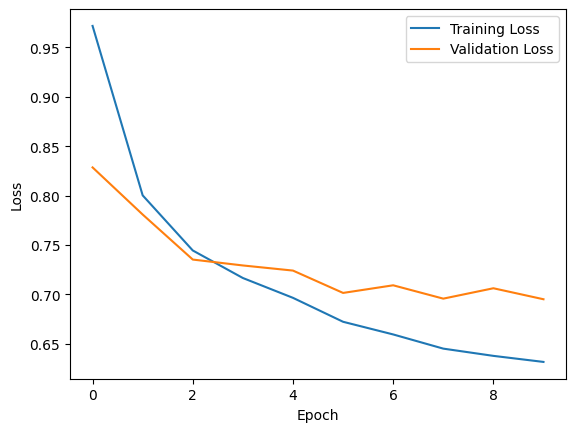

In [73]:
with open("results/attempt8_2.txt", "r") as f:
    print(f.read())
LOSS = np.loadtxt("results/attempt8_2_loss.txt", usecols=0)
val_LOSS = np.loadtxt("results/attempt8_2_loss.txt", usecols=1)
plot_loss(LOSS, val_LOSS)

**Conclusions:**
- dropout lowered variance by a bit

## attempt 8.3

Added `label smoothing` of `0.1` to the loss function `Cross Entropy Loss` to improve the generalization

In [ ]:

from torchvision.models import resnet50

# Load ResNet50 with pretrained weights
resnet50 = resnet50(weights=True)
# Replace ResNet50 last fully connected layers to output 10 features
in_features = resnet50.fc.in_features

resnet50.fc = nn.Sequential(
            nn.Dropout(0),
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

from types import MethodType

def fit(self, X, y):
    self.optimizer.zero_grad()
    y_pred = self.forward(X)
    loss = self.loss_fn(y_pred, y)
    loss.backward()
    self.optimizer.step()
    return loss.item()

resnet50.fit = MethodType(fit, resnet50)

# By default batch_size=128
train_loader, val_loader = load_data(128)

resnet50.optimizer = optim.Adam(resnet50.parameters(), lr=0.001, weight_decay=0)
resnet50.loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
LOSS, val_LOSS= train(resnet50, train_loader, val_loader, 10)


train accuracy: 97.6
validation accuracy: 91.63


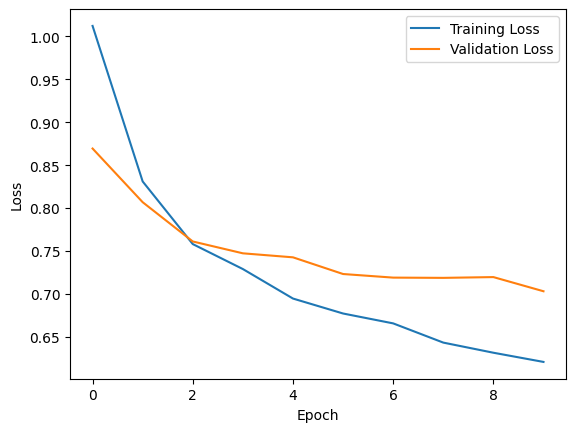

In [67]:
with open("results/attempt8_3.txt", "r") as f:
    print(f.read())
LOSS = np.loadtxt("results/attempt8_3_loss.txt", usecols=0)
val_LOSS = np.loadtxt("results/attempt8_3_loss.txt", usecols=1)
plot_loss(LOSS, val_LOSS)

**Conclusions:**
- label smoothing lowered variance by a bit

## attempt 8.4

Combined previous attempts results dropout rate of `0.2` and label label smoothing of `0.1`

In [ ]:

from torchvision.models import resnet50

# Load ResNet50 with pretrained weights
resnet50 = resnet50(weights=True)
# Replace ResNet50 last fully connected layers to output 10 features
in_features = resnet50.fc.in_features

resnet50.fc = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

from types import MethodType

def fit(self, X, y):
    self.optimizer.zero_grad()
    y_pred = self.forward(X)
    loss = self.loss_fn(y_pred, y)
    loss.backward()
    self.optimizer.step()
    return loss.item()

resnet50.fit = MethodType(fit, resnet50)

# By default batch_size=128
train_loader, val_loader = load_data(128)

resnet50.optimizer = optim.Adam(resnet50.parameters(), lr=0.001, weight_decay=0)
resnet50.loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
LOSS, val_LOSS= train(resnet50, train_loader, val_loader, 10)

train accuracy: 97.135
validation accuracy: 91.23


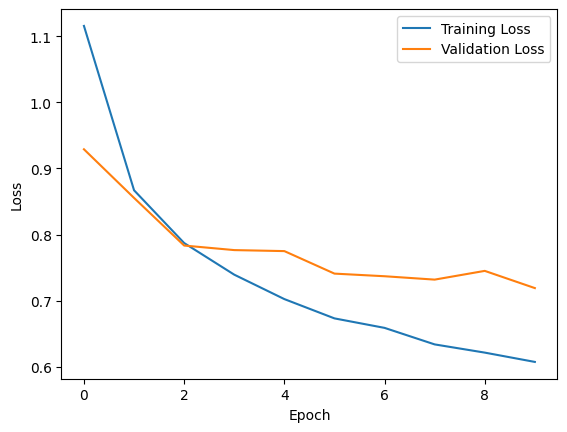

In [53]:
with open("results/attempt8_4.txt", "r") as f:
    print(f.read())
LOSS = np.loadtxt("results/attempt8_4_loss.txt", usecols=0)
val_LOSS = np.loadtxt("results/attempt8_4_loss.txt", usecols=1)
plot_loss(LOSS, val_LOSS)

**Conclusions:**
- The combination of the 2 didn't yield results as expected

## Attempt 8.5

With attempt 8.4 hyper-parameters, trying out different batch sizes
in this attempt I'll try batch size `64` which is lower from my default of `128`

In [ ]:
from torchvision.models import resnet50

# Load ResNet50 with pretrained weights
resnet50 = resnet50(weights=True)
# Replace ResNet50 last fully connected layers to output 10 features
in_features = resnet50.fc.in_features

resnet50.fc = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

from types import MethodType

def fit(self, X, y):
    self.optimizer.zero_grad()
    y_pred = self.forward(X)
    loss = self.loss_fn(y_pred, y)
    loss.backward()
    self.optimizer.step()
    return loss.item()

resnet50.fit = MethodType(fit, resnet50)

# By default batch_size=128
train_loader, val_loader = load_data(64)

resnet50.optimizer = optim.Adam(resnet50.parameters(), lr=0.001, weight_decay=0)
resnet50.loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
LOSS, val_LOSS= train(resnet50, train_loader, val_loader, 10)

train accuracy: 96.1725
validation accuracy: 90.05


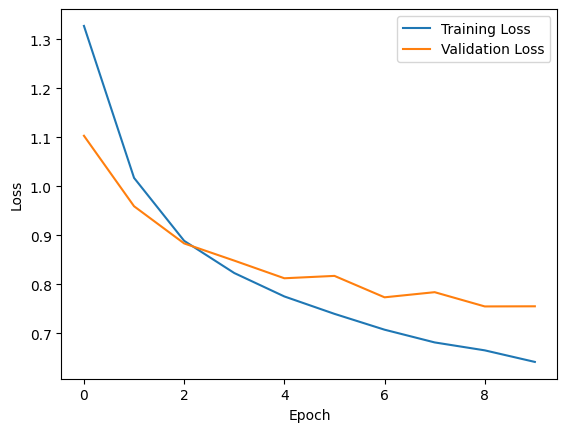

In [4]:
with open("results/attempt8_5.txt", "r") as f:
    print(f.read())
LOSS = np.loadtxt("results/attempt8_5_loss.txt", usecols=0)
val_LOSS = np.loadtxt("results/attempt8_5_loss.txt", usecols=1)
plot_loss(LOSS, val_LOSS)

**Conclusions:**
- bias gotten higher, I'll try higher batch size next

## Attempt 8.6

With attempt 8.4 hyper-parameters, trying out different batch sizes
in this attempt I'll try batch size `256` which is lower from my default of `128`

In [ ]:

from torchvision.models import resnet50

# Load ResNet50 with pretrained weights
resnet50 = resnet50(weights=True)
# Replace ResNet50 last fully connected layers to output 10 features
in_features = resnet50.fc.in_features

resnet50.fc = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

from types import MethodType

def fit(self, X, y):
    self.optimizer.zero_grad()
    y_pred = self.forward(X)
    loss = self.loss_fn(y_pred, y)
    loss.backward()
    self.optimizer.step()
    return loss.item()

resnet50.fit = MethodType(fit, resnet50)

# By default batch_size=128
train_loader, val_loader = load_data(256)

resnet50.optimizer = optim.Adam(resnet50.parameters(), lr=0.001, weight_decay=0)
resnet50.loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
LOSS, val_LOSS= train(resnet50, train_loader, val_loader, 10)

train accuracy: 97.7225
validation accuracy: 91.96


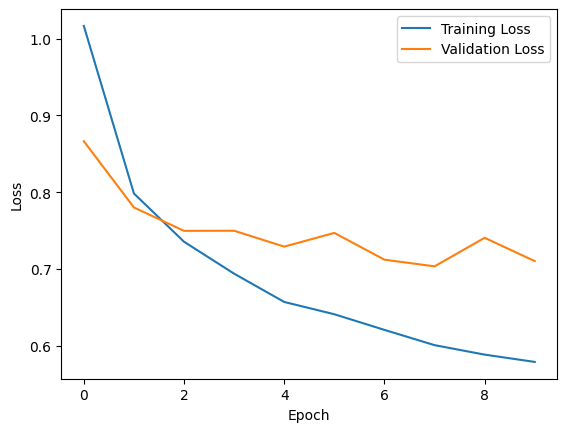

In [5]:
with open("results/attempt8_6.txt", "r") as f:
    print(f.read())
LOSS = np.loadtxt("results/attempt8_6_loss.txt", usecols=0)
val_LOSS = np.loadtxt("results/attempt8_6_loss.txt", usecols=1)
plot_loss(LOSS, val_LOSS)

**Conclusions:**
- higher batch sized yielded lower variance

## Attempt 8.7

using Attempt 8.6 Added early stopping and more epochs

In [ ]:
from torchvision.models import resnet50

# Load ResNet50 with pretrained weights
resnet50 = resnet50(weights=True)
# Replace ResNet50 last fully connected layers to output 10 features
in_features = resnet50.fc.in_features

resnet50.fc = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

from types import MethodType

def fit(self, X, y):
    self.optimizer.zero_grad()
    y_pred = self.forward(X)
    loss = self.loss_fn(y_pred, y)
    loss.backward()
    self.optimizer.step()
    return loss.item()

resnet50.fit = MethodType(fit, resnet50)

train_loader, val_loader = load_data(256)

resnet50.optimizer = optim.Adam(resnet50.parameters(), lr=0.001, weight_decay=0)
resnet50.loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)
LOSS, val_LOSS= train(resnet50, train_loader, val_loader, 100, 5, True)

train accuracy: 98.06
validation accuracy: 92.31


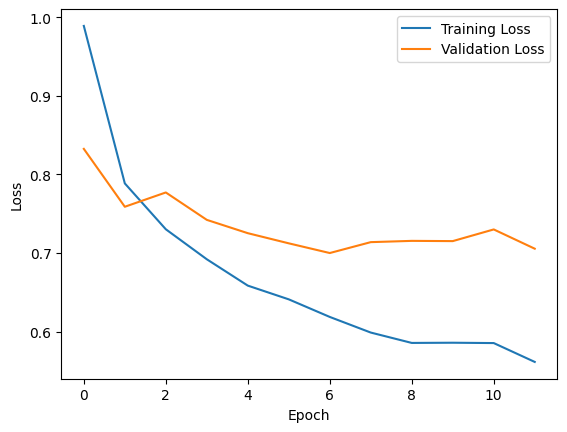

In [6]:
with open("results/attempt8_7.txt", "r") as f:
    print(f.read())
LOSS = np.loadtxt("results/attempt8_7_loss.txt", usecols=0)
val_LOSS = np.loadtxt("results/attempt8_7_loss.txt", usecols=1)
plot_loss(LOSS, val_LOSS)

**Conclusions:**
- as can be expected higher epochs with early stopping lowered variance

## Attempt 8.8

Since I'm using a pretrained ResNet-50, ensure the lower layers are fine-tuned instead of frozen: By `requires_grad = True` to all the model's parameters

In [ ]:
from torchvision.models import resnet50

# Load ResNet50 with pretrained weights
resnet50 = resnet50(weights=True)
# Replace ResNet50 last fully connected layers to output 10 features
in_features = resnet50.fc.in_features

resnet50.fc = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

from types import MethodType

def fit(self, X, y):
    self.optimizer.zero_grad()
    y_pred = self.forward(X)
    loss = self.loss_fn(y_pred, y)
    loss.backward()
    self.optimizer.step()
    return loss.item()

resnet50.fit = MethodType(fit, resnet50)

train_loader, val_loader = load_data(256)

resnet50.optimizer = optim.Adam(resnet50.parameters(), lr=0.001, weight_decay=0)
resnet50.loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

# Ensure all layers are trainable (full fine-tuning)
for param in resnet50.parameters():
    param.requires_grad = True  # Allow updates to all layers

LOSS, val_LOSS= train(resnet50, train_loader, val_loader, 100, 5, True)


train accuracy: 98.8025
validation accuracy: 92.61


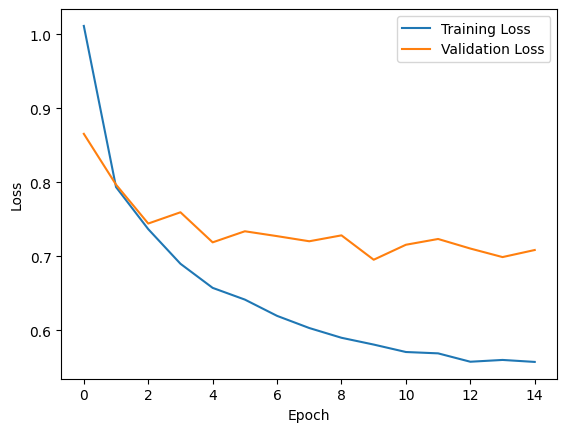

In [7]:
with open("results/attempt8_8.txt", "r") as f:
    print(f.read())
LOSS = np.loadtxt("results/attempt8_8_loss.txt", usecols=0)
val_LOSS = np.loadtxt("results/attempt8_8_loss.txt", usecols=1)
plot_loss(LOSS, val_LOSS)

**Conclusions:**
- By fine-tuning the model achieved lower bias

# Final Results

In [ ]:
import torch
from torch import nn
from torch.utils.data import DataLoader
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torchvision.transforms import ToTensor
from torchvision.datasets import CIFAR10

import numpy as np
import matplotlib.pyplot as plt
import time

device = (
    "cuda"
    if torch.cuda.is_available()
    else "mps"
    if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Using {device} device")

torch.set_default_device(device)

Using cuda device


In [ ]:
def plot_loss(LOSS, Val_LOSS=None):
    plt.plot(LOSS, label='Training Loss')
    if Val_LOSS is not None:
        plt.plot(Val_LOSS, label='Validation Loss')
        plt.legend()
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.show()

def time_format(tm):
    houres = int(tm // 3600)
    tm = tm % 3600
    minutes = int(tm // 60)
    seconds = int(tm % 60)
    milliseconds = int((tm % 1) * 1000)
    return f"{houres:02}:{minutes:02}:{seconds:02}:{milliseconds:03}"

def accuracy(model, loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for data in loader:
            X, y = data
            X, y = X.to(device), y.to(device)
            outputs = model(X)
            _, predicted = torch.max(outputs.data, 1)
            total += y.size(0)
            correct += (predicted == y).sum().item()

    return 100 * correct / total

In [ ]:
def load_data(batch_size=128):

    # values specific to CIFAR-10, meaning they are computed as the mean and standard deviation of the training set.
    normalize = transforms.Normalize(
        mean=[0.4914, 0.4822, 0.4465],
        std=[0.2023, 0.1994, 0.2010],
    )

    transform_train = transforms.Compose([
        transforms.Resize((224, 224)),  # Resize to match ResNet50 input size
        transforms.RandomHorizontalFlip(0.5),
        transforms.ToTensor(),
        normalize,
    ])

    transform_val = transforms.Compose([
        transforms.Resize((224, 224)),  # Resize to match ResNet50 input size
        transforms.ToTensor(),
        normalize,
    ])
    generator = torch.Generator(device=device)

    train_set = torchvision.datasets.CIFAR10(root='./data', train=True,
                                           download=True, transform=transform_train)


    train_size = int(0.8 * len(train_set))  # 80% for training
    val_size = len(train_set) - train_size  # 20% for validation
    train_set, val_set = torch.utils.data.random_split(train_set, [train_size, val_size],
                                                      generator=torch.Generator(device=device))

    val_set.dataset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                           download=True, transform=transform_val)

    train_loader = torch.utils.data.DataLoader(train_set, batch_size=batch_size,
                                              shuffle=True, num_workers=0, pin_memory=False,
                                              generator=torch.Generator(device=device))

    val_loader = torch.utils.data.DataLoader(val_set, batch_size=batch_size,
                                              shuffle=True, num_workers=0, pin_memory=False,
                                              generator=torch.Generator(device=device))
    return train_loader, val_loader


def load_test(batch_size=128):
    # values specific to CIFAR-10, meaning they are computed as the mean and standard deviation of the test set.
    normalize = transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225],
    )
    transform = transforms.Compose([
        transforms.Resize((224, 224)),  # Resize to match ResNet50 input size
        transforms.ToTensor(),
        normalize,
    ])

    test_set = torchvision.datasets.CIFAR10(root='./data', train=False,
                                           download=True, transform=transform)
    test_loader = torch.utils.data.DataLoader(test_set, batch_size=batch_size,
                                             shuffle=False, num_workers=0,  pin_memory=False,
                                             generator=torch.Generator(device=device))
    return test_loader


In [ ]:
def train(model, train_loader, val_loader=None, epochs=20, patience=5, early_stopping=False, enable_printing=True):
    model.train()
    LOSS = []
    Val_LOSS = []
    tm = time.time()
    best_val_loss = float('inf')
    epochs_no_improve = 0
    early_stop = False

    if enable_printing:
        print('Starting Training')

    for epoch in range(epochs):  # loop over the dataset multiple times
        if early_stop and early_stopping:
            break

        # Training phase
        batch_loss = []
        for i, data in enumerate(train_loader, 0):
            X, y = data
            X, y = X.to(device), y.to(device)
            l = model.fit(X, y)
            batch_loss.append(l)
        LOSS.append(np.mean(batch_loss))

        # Validation phase
        if val_loader is not None:
            with torch.no_grad():
                val_batch_loss = []
                for i, data in enumerate(val_loader, 0):
                    X_v, y_v = data
                    X_v, y_v = X_v.to(device), y_v.to(device)
                    y_pred = model.forward(X_v)
                    loss = model.loss_fn(y_pred, y_v)
                    val_batch_loss.append(loss.item())
                val_loss = np.mean(val_batch_loss)
                Val_LOSS.append(val_loss)

                # Early stopping logic
                if early_stopping:
                    if val_loss < best_val_loss:
                        best_val_loss = val_loss
                        epochs_no_improve = 0
                    else:
                        epochs_no_improve += 1

                    if epochs_no_improve >= patience:
                        if enable_printing:
                            print(f"Early stopping triggered after {epoch + 1} epochs")
                        early_stop = True
                        break

        if enable_printing:
            print(f"Epoch: {epoch + 1:3} | {time_format(time.time() - tm)} | Loss: {LOSS[epoch]:.4f}", end="")
            if val_loader is not None:
                print(f" | Val Loss: {Val_LOSS[-1]:.4f}")
            else:
                print()

    if enable_printing and not early_stop:
        print(f"Finished Training | {time_format(time.time() - tm)}")
    return LOSS if val_loader is None else (LOSS, Val_LOSS)


In [ ]:
from torchvision.models import resnet50

# Load ResNet50 with pretrained weights
resnet50 = resnet50(weights=True)
# Replace ResNet50 last fully connected layers to output 10 features
in_features = resnet50.fc.in_features

resnet50.fc = nn.Sequential(
            nn.Dropout(0.2),
            nn.Linear(in_features, 1024),
            nn.ReLU(),
            nn.Linear(1024, 512),
            nn.ReLU(),
            nn.Linear(512, 10)
        )

from types import MethodType

def fit(self, X, y):
    self.optimizer.zero_grad()
    y_pred = self.forward(X)
    loss = self.loss_fn(y_pred, y)
    loss.backward()
    self.optimizer.step()
    return loss.item()

resnet50.fit = MethodType(fit, resnet50)

train_loader, val_loader = load_data(256)

resnet50.optimizer = optim.Adam(resnet50.parameters(), lr=0.001, weight_decay=0)
resnet50.loss_fn = nn.CrossEntropyLoss(label_smoothing=0.1)

# Ensure all layers are trainable (full fine-tuning)
for param in resnet50.parameters():
    param.requires_grad = True  # Allow updates to all layers

Files already downloaded and verified
Files already downloaded and verified


> Loading Attempt 8.8 trained model

In [ ]:
resnet50.load_state_dict(torch.load(f'trained/attempt8_8'))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
resnet50.to(device)

test_loader = load_test(256)
with torch.no_grad():
    acc_test = accuracy(resnet50, test_loader)
print("Test accuracy: ", acc_test)

Files already downloaded and verified
Test accuracy:  92.0
